In [1]:

# Machine Learning Based Security Threat Detection
# Robustness and Generalization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv('/content/phishing-dataset-variation.csv')

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 88647
Number of columns: 112


,qty_dot_url,qty_hyphen_url,qty_underline_url,qty_slash_url,qty_questionmark_url,qty_equal_url,qty_at_url,qty_and_url,qty_exclamation_url,qty_space_url,...,qty_ip_resolved,qty_nameservers,qty_mx_servers,ttl_hostname,tls_ssl_certificate,qty_redirects,url_google_index,domain_google_index,url_shortened,phishing
0,3,0,0,1,0,0,0,0,0,0,...,1,2,0,892,0,0,0,0,0,1
1,5,0,1,3,0,3,0,2,0,0,...,1,2,1,9540,1,0,0,0,0,1
2,2,0,0,1,0,0,0,0,0,0,...,1,2,3,589,1,0,0,0,0,0
3,4,0,2,5,0,0,0,0,0,0,...,1,2,0,292,1,0,0,0,0,1
4,2,0,0,0,0,0,0,0,0,0,...,1,2,1,3597,0,1,0,0,0,0


In [3]:

print("Dataset dimensions:", df.shape)

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df['phishing'].value_counts())


Dataset dimensions: (88647, 112)

Duplicate rows:
1438

Missing values:
0

Column names:
['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url', 'qty_tilde_url', 'qty_comma_url', 'qty_plus_url', 'qty_asterisk_url', 'qty_hashtag_url', 'qty_dollar_url', 'qty_percent_url', 'qty_tld_url', 'length_url', 'qty_dot_domain', 'qty_hyphen_domain', 'qty_underline_domain', 'qty_slash_domain', 'qty_questionmark_domain', 'qty_equal_domain', 'qty_at_domain', 'qty_and_domain', 'qty_exclamation_domain', 'qty_space_domain', 'qty_tilde_domain', 'qty_comma_domain', 'qty_plus_domain', 'qty_asterisk_domain', 'qty_hashtag_domain', 'qty_dollar_domain', 'qty_percent_domain', 'qty_vowels_domain', 'domain_length', 'domain_in_ip', 'server_client_domain', 'qty_dot_directory', 'qty_hyphen_directory', 'qty_underline_directory', 'qty_slash_directory', 'qty_questionmark_directory', 'qty_equal_di

In [4]:

# Remove duplicate records
df_clean = df.drop_duplicates().reset_index(drop=True)

# Separate features and target variable
X = df_clean.drop(columns=['phishing'])
y = df_clean['phishing']

print("Original samples:", len(df))
print("Cleaned samples:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))
print("Number of features:", X.shape[1])

print("\nCleaned class distribution:")
print(y.value_counts())


Original samples: 88647
Cleaned samples: 87209
Duplicates removed: 1438
Number of features: 111

Cleaned class distribution:
phishing
0    56712
1    30497
Name: count, dtype: int64


In [5]:

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 69767
Testing samples: 17442

Training class distribution:
phishing
0    45369
1    24398
Name: count, dtype: int64

Testing class distribution:
phishing
0    11343
1     6099
Name: count, dtype: int64


In [6]:

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [7]:

# Create Histogram Gradient Boosting model
hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=42
)

# Train the model
hgb_model.fit(X_train, y_train)

print("Histogram Gradient Boosting training completed!")


Histogram Gradient Boosting training completed!


In [8]:

# Function to evaluate model performance
def evaluate_model(model, X_data, y_data):

    predictions = model.predict(X_data)

    tn, fp, fn, tp = confusion_matrix(
        y_data, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(y_data, predictions),
        "Recall": recall_score(y_data, predictions),
        "F1 Score": f1_score(y_data, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_data, predictions
        ),
        "False Positive Rate": fp / (fp + tn)
    }

# Evaluate both models
baseline_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_model, X_test, y_test
    ),
    "Gradient Boosting": evaluate_model(
        hgb_model, X_test, y_test
    )
}).T

# Display results as percentages
print("Baseline Performance Results (%)")
display((baseline_results * 100).round(2))


Baseline Performance Results (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,96.93,95.53,95.69,95.61,96.64,2.41
Gradient Boosting,96.65,95.27,95.13,95.20,96.30,2.54


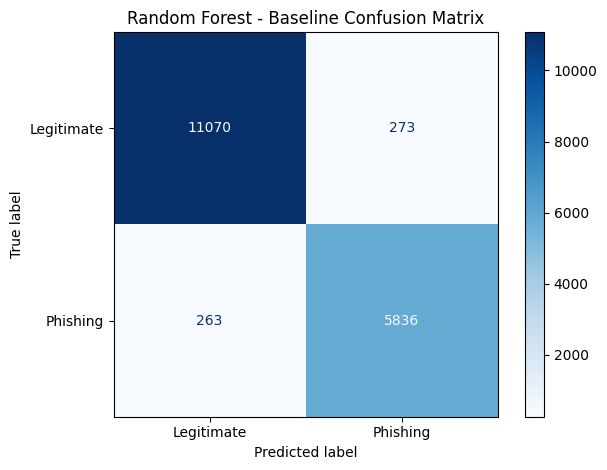

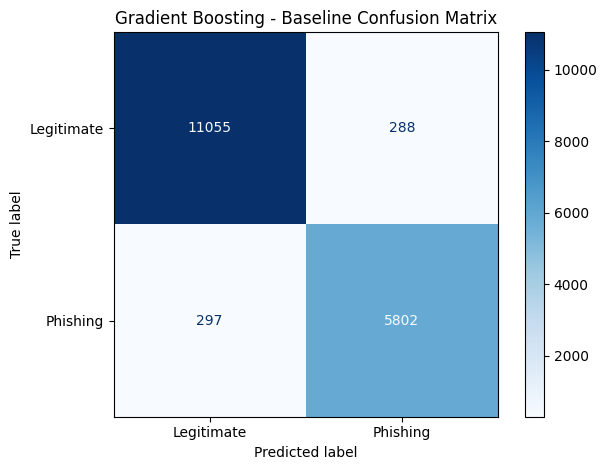

In [9]:

# Generate confusion matrices
models = {
    "Random Forest": rf_model,
    "Gradient Boosting": hgb_model
}

for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Phishing"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(name + " - Baseline Confusion Matrix")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(filename + "_confusion_matrix.png",
                dpi=300, bbox_inches="tight")

    plt.show()


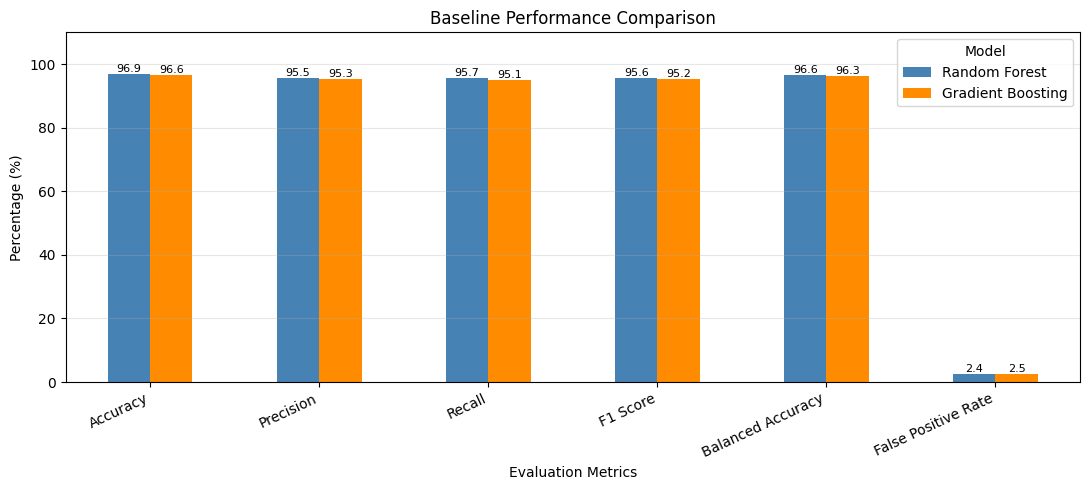

In [10]:

# Compare baseline model performance
ax = (baseline_results * 100).T.plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Baseline Performance Comparison")
plt.ylabel("Percentage (%)")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 110)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)

plt.tight_layout()
plt.savefig("baseline_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Save numerical results
baseline_results.to_csv("baseline_results.csv")


In [17]:

# Select 20 URL-related features
url_features = [
    col for col in X_train.columns
    if col.endswith("_url")
][:20]

print("Selected features:", len(url_features))
print(url_features)

# Calculate replacement values from training data
replacement_values = X_train[url_features].median()

# Create a modified copy of the testing data
X_modified = X_test.copy()

# Simulate unavailable feature information
for col in url_features:
    X_modified[col] = replacement_values[col]

print("\nModified testing dataset created!")
print("Testing samples:", len(X_modified))


Selected features: 20
['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url', 'qty_tilde_url', 'qty_comma_url', 'qty_plus_url', 'qty_asterisk_url', 'qty_hashtag_url', 'qty_dollar_url', 'qty_percent_url', 'qty_tld_url', 'length_url', 'email_in_url']

Modified testing dataset created!
Testing samples: 17442


In [12]:

# Evaluate models on modified data
robustness_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_model, X_modified, y_test
    ),
    "Gradient Boosting": evaluate_model(
        hgb_model, X_modified, y_test
    )
}).T

print("Robustness Experiment Results (%)")
display((robustness_results * 100).round(2))

# Calculate performance decrease
performance_drop = (
    baseline_results - robustness_results
) * 100

print("\nPerformance Change (Percentage Points)")
display(performance_drop.round(2))

# Save results
robustness_results.to_csv("robustness_results.csv")
performance_drop.to_csv("performance_drop.csv")


Robustness Experiment Results (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,96.39,95.21,94.44,94.82,95.94,2.56
Gradient Boosting,71.50,99.47,18.59,31.33,59.27,0.05



Performance Change (Percentage Points)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,0.53,0.32,1.25,0.79,0.70,-0.15
Gradient Boosting,25.15,-4.20,76.54,63.87,37.03,2.49


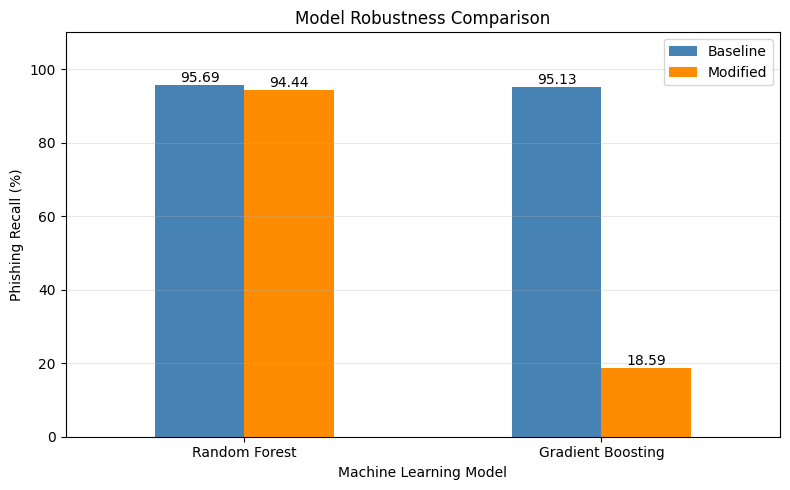

In [13]:

# Compare phishing recall before and after modification
recall_comparison = pd.DataFrame({
    "Baseline": baseline_results["Recall"] * 100,
    "Modified": robustness_results["Recall"] * 100
})

ax = recall_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Model Robustness Comparison")
plt.ylabel("Phishing Recall (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.tight_layout()
plt.savefig("robustness_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [14]:

# Calculate median URL length
median_length = df_clean["length_url"].median()

# Separate shorter and longer URLs
short_urls = df_clean[
    df_clean["length_url"] <= median_length
]

long_urls = df_clean[
    df_clean["length_url"] > median_length
]

# Prepare training data
X_short = short_urls.drop(columns=["phishing"])
y_short = short_urls["phishing"]

# Prepare testing data
X_long = long_urls.drop(columns=["phishing"])
y_long = long_urls["phishing"]

print("Median URL length:", median_length)
print("Short URL samples:", len(short_urls))
print("Long URL samples:", len(long_urls))

print("\nShort URL class distribution:")
print(y_short.value_counts())

print("\nLong URL class distribution:")
print(y_long.value_counts())


Median URL length: 22.0
Short URL samples: 44313
Long URL samples: 42896

Short URL class distribution:
phishing
0    40575
1     3738
Name: count, dtype: int64

Long URL class distribution:
phishing
1    26759
0    16137
Name: count, dtype: int64


In [15]:

# Random Forest generalization model
rf_general = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_general.fit(X_short, y_short)

# Gradient Boosting generalization model
hgb_general = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=42
)

hgb_general.fit(X_short, y_short)

# Evaluate on longer URLs
generalization_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_general, X_long, y_long
    ),
    "Gradient Boosting": evaluate_model(
        hgb_general, X_long, y_long
    )
}).T

print("Generalization Results (%)")
display((generalization_results * 100).round(2))

generalization_results.to_csv(
    "generalization_results.csv"
)


Generalization Results (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,87.06,90.89,88.08,89.46,86.72,14.64
Gradient Boosting,85.36,92.87,82.90,87.60,86.17,10.56


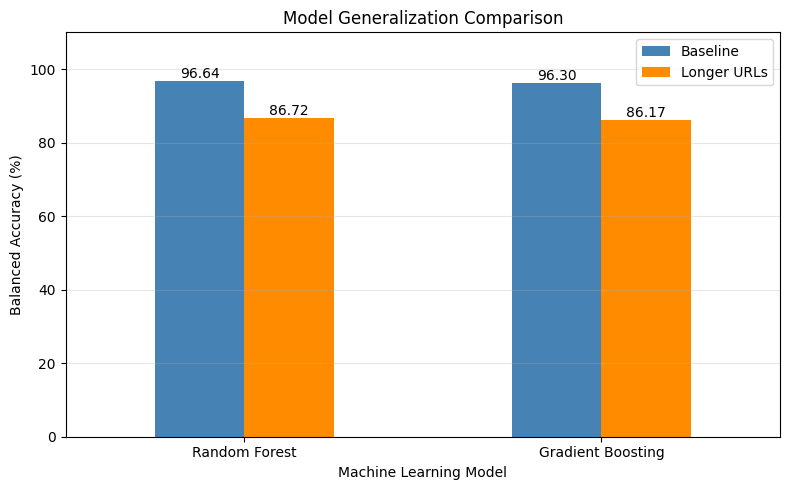

In [16]:

generalization_comparison = pd.DataFrame({
    "Baseline":
        baseline_results["Balanced Accuracy"] * 100,
    "Longer URLs":
        generalization_results["Balanced Accuracy"] * 100
})

ax = generalization_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Model Generalization Comparison")
plt.ylabel("Balanced Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.tight_layout()
plt.savefig("generalization_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [18]:

# Create modified training samples
X_train_modified = X_train.copy()

for col in url_features:
    X_train_modified[col] = replacement_values[col]

# Combine original and modified training data
X_augmented = pd.concat(
    [X_train, X_train_modified],
    ignore_index=True
)

y_augmented = pd.concat(
    [y_train, y_train],
    ignore_index=True
)

print("Original training samples:", len(X_train))
print("Augmented training samples:", len(X_augmented))


Original training samples: 69767
Augmented training samples: 139534


In [19]:

# Train defended Random Forest
rf_defended = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_defended.fit(X_augmented, y_augmented)

# Train defended Gradient Boosting
hgb_defended = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=42
)

hgb_defended.fit(X_augmented, y_augmented)

print("Defended models trained successfully!")


Defended models trained successfully!


In [20]:

# Evaluate defended models on normal data
defense_clean_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_defended, X_test, y_test
    ),
    "Gradient Boosting": evaluate_model(
        hgb_defended, X_test, y_test
    )
}).T

# Evaluate defended models on modified data
defense_modified_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_defended, X_modified, y_test
    ),
    "Gradient Boosting": evaluate_model(
        hgb_defended, X_modified, y_test
    )
}).T

print("Defended Models - Normal Data (%)")
display((defense_clean_results * 100).round(2))

print("\nDefended Models - Modified Data (%)")
display((defense_modified_results * 100).round(2))

defense_clean_results.to_csv(
    "defense_clean_results.csv"
)

defense_modified_results.to_csv(
    "defense_modified_results.csv"
)


Defended Models - Normal Data (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,97.14,95.87,95.95,95.91,96.86,2.22
Gradient Boosting,96.59,95.07,95.18,95.12,96.26,2.65



Defended Models - Modified Data (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,97.14,95.69,96.15,95.92,96.91,2.33
Gradient Boosting,96.58,95.08,95.15,95.12,96.25,2.64


In [21]:

# Remove the 20 selected URL features
X_train_reduced = X_train.drop(columns=url_features)
X_test_reduced = X_test.drop(columns=url_features)

print("Original features:", X_train.shape[1])
print("Remaining features:", X_train_reduced.shape[1])

# Train reduced Random Forest
rf_reduced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_reduced, y_train)

# Train reduced Gradient Boosting
hgb_reduced = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=42
)

hgb_reduced.fit(X_train_reduced, y_train)

# Evaluate reduced models
feature_removal_results = pd.DataFrame({
    "Random Forest": evaluate_model(
        rf_reduced, X_test_reduced, y_test
    ),
    "Gradient Boosting": evaluate_model(
        hgb_reduced, X_test_reduced, y_test
    )
}).T

print("\nFeature Removal Results (%)")
display((feature_removal_results * 100).round(2))

feature_removal_results.to_csv(
    "feature_removal_results.csv"
)


Original features: 111
Remaining features: 91

Feature Removal Results (%)


,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,False Positive Rate
Random Forest,97.10,95.64,96.08,95.86,96.86,2.35
Gradient Boosting,96.62,95.02,95.33,95.17,96.32,2.69


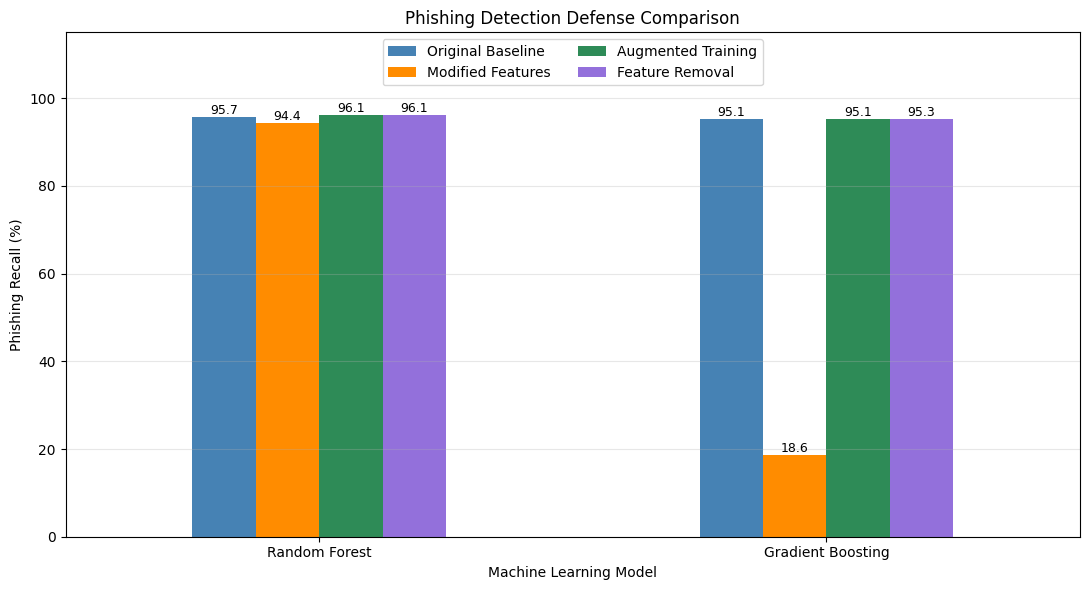

In [22]:

defense_comparison = pd.DataFrame({
    "Original Baseline":
        baseline_results["Recall"] * 100,

    "Modified Features":
        robustness_results["Recall"] * 100,

    "Augmented Training":
        defense_modified_results["Recall"] * 100,

    "Feature Removal":
        feature_removal_results["Recall"] * 100
})

ax = defense_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=[
        "steelblue",
        "darkorange",
        "seagreen",
        "mediumpurple"
    ]
)

plt.title("Phishing Detection Defense Comparison")
plt.ylabel("Phishing Recall (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 115)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper center", ncol=2)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=9)

plt.tight_layout()
plt.savefig(
    "defense_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [23]:

# Consolidate all experimental results
final_results = pd.concat({
    "Baseline": baseline_results,
    "Robustness": robustness_results,
    "Generalization": generalization_results,
    "Augmentation - Normal": defense_clean_results,
    "Augmentation - Modified": defense_modified_results,
    "Feature Removal": feature_removal_results
})

final_results.index.names = ["Experiment", "Model"]

final_results = (final_results * 100).round(2)

display(final_results)

final_results.to_csv("final_research_results.csv")


Accuracy  Precision  Recall  \
Experiment              Model                                            
Baseline                Random Forest         96.93      95.53   95.69   
                        Gradient Boosting     96.65      95.27   95.13   
Robustness              Random Forest         96.39      95.21   94.44   
                        Gradient Boosting     71.50      99.47   18.59   
Generalization          Random Forest         87.06      90.89   88.08   
                        Gradient Boosting     85.36      92.87   82.90   
Augmentation - Normal   Random Forest         97.14      95.87   95.95   
                        Gradient Boosting     96.59      95.07   95.18   
Augmentation - Modified Random Forest         97.14      95.69   96.15   
                        Gradient Boosting     96.58      95.08   95.15   
Feature Removal         Random Forest         97.10      95.64   96.08   
                        Gradient Boosting     96.62      95.02   95.33   

                                           F1 Score  Balanced Accuracy  \
Experiment              Model                                            
Baseline                Random Forest         95.61              96.64   
                        Gradient Boosting     95.20              96.30   
Robustness              Random Forest         94.82              95.94   
                        Gradient Boosting     31.33              59.27   
Generalization          Random Forest         89.46              86.72   
                        Gradient Boosting     87.60              86.17   
Augmentation - Normal   Random Forest         95.91              96.86   
                        Gradient Boosting     95.12              96.26   
Augmentation - Modified Random Forest         95.92              96.91   
                        Gradient Boosting     95.12              96.25   
Feature Removal         Random Forest         95.86              96.86   
                        Gradient Boosting     95.17              96.32   

                                           False Positive Rate  
Experiment              Model                                   
Baseline                Random Forest                     2.41  
                        Gradient Boosting                 2.54  
Robustness              Random Forest                     2.56  
                        Gradient Boosting                 0.05  
Generalization          Random Forest                    14.64  
                        Gradient Boosting                10.56  
Augmentation - Normal   Random Forest                     2.22  
                        Gradient Boosting                 2.65  
Augmentation - Modified Random Forest                     2.33  
                        Gradient Boosting                 2.64  
Feature Removal         Random Forest                     2.35  
                        Gradient Boosting                 2.69

In [24]:

X_modified_reduced = X_modified.drop(columns=url_features)

for name, model in {
    "Random Forest": rf_reduced,
    "Gradient Boosting": hgb_reduced
}.items():

    identical = np.array_equal(
        model.predict(X_test_reduced),
        model.predict(X_modified_reduced)
    )

    print(name, "- Identical predictions:", identical)


Random Forest - Identical predictions: True
Gradient Boosting - Identical predictions: True


In [25]:

import os
import zipfile
from google.colab import files

with zipfile.ZipFile(
    "Research_Artifacts.zip", "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in os.listdir("/content"):
        if filename.endswith((".png", ".csv")):
            if filename != "phishing-dataset-variation.csv":
                zip_file.write(
                    "/content/" + filename,
                    arcname=filename
                )

print("Research artifacts exported successfully!")

files.download("Research_Artifacts.zip")


Research artifacts exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>